# Prediksi Kebakaran Hutan dengan Machine Learning
### Perbandingan Random Forest dan Logistic Regression
**Tema: SDGs 15 (Ekosistem Daratan), menjaga hutan**

Alur notebook: 1. Masalah → 2. Data → 3. Persiapan Data → 4. Melatih Model → 5. Evaluasi → 6. Penerapan → 7. Pemantauan

## 1. Masalah

**Pertanyaan:** bisakah kita menebak apakah suatu hari **terjadi kebakaran hutan atau tidak**, dari data cuaca dan
data kekeringan hari itu?

- **Jenis masalah:** klasifikasi dua kelas (*Kebakaran* atau *Tidak Kebakaran*).
- **Dua model yang dibandingkan:** Random Forest dan Logistic Regression.
- **Manfaat:** membantu mengenali hari yang rawan kebakaran sehingga pencegahan bisa dilakukan lebih awal.

## 2. Data

**Sumber:** *The Extended Algerian Forest Fires Dataset* (Faroudja Abid, IEEE Dataport / Mendeley Data, 2026).
Berisi **1215 hari pengamatan** dari **10 lokasi** di Aljazair (tahun 2012, 2017, dan 2021).
Satu baris = satu hari di satu lokasi. Ada 633 hari kebakaran dan 582 hari tidak kebakaran.

### Kamus Fitur: arti setiap singkatan

Ada **10 fitur** (data masukan). Empat pertama adalah cuaca biasa. Enam sisanya adalah **indeks kekeringan**,
yaitu angka hasil hitungan dari sistem peringatan kebakaran hutan, yang menggambarkan seberapa kering dan mudah
terbakarnya hutan.

| Nama di notebook | Kepanjangan | Artinya dalam bahasa sederhana | Makin besar berarti |
|---|---|---|---|
| `Suhu` | Temperature | Suhu udara siang hari (°C) | Makin panas, makin rawan |
| `Kelembapan` | Relative Humidity (RH) | Banyaknya uap air di udara (%) | Makin kecil, udara makin kering, makin rawan |
| `Angin` | Wind speed (Ws) | Kecepatan angin (km/jam) | Api makin cepat menyebar |
| `Hujan` | Rain | Curah hujan seharian (mm) | Makin basah, makin aman |
| `FFMC` | Fine Fuel Moisture Code | Kekeringan **daun dan ranting kering di permukaan tanah** | Makin kering, makin mudah menyala |
| `DMC` | Duff Moisture Code | Kekeringan **tumpukan daun lapuk** di bawah permukaan | Makin kering, makin mudah terbakar |
| `DC` | Drought Code | Kekeringan **lapisan tanah yang dalam** (akibat kemarau panjang) | Makin kering, api makin sulit padam |
| `ISI` | Initial Spread Index | Seberapa cepat api **menyebar** di awal (gabungan FFMC dan angin) | Api makin cepat menyebar |
| `BUI` | Buildup Index | Jumlah **bahan bakar** (daun, ranting, serasah) yang tersedia untuk terbakar (gabungan DMC dan DC) | Makin banyak bahan yang bisa terbakar |
| `FWI` | Fire Weather Index | **Nilai bahaya api secara keseluruhan** (gabungan ISI dan BUI) | Makin berbahaya |

**Analogi api unggun:** kayu basah susah dinyalakan, kayu kering mudah menyala (FFMC, DMC, DC). Angin kencang membuat
api cepat melebar (ISI). Makin banyak kayu, makin besar apinya (BUI). FWI adalah "nilai rapor" bahaya apinya secara keseluruhan.
Di sini "bahan bakar" artinya daun, ranting, dan serasah, bukan bensin.

**Label (jawaban yang ditebak):** `Status` → *Kebakaran* atau *Tidak Kebakaran*.

**Bukan fitur:** `DATE` (tanggal, sebagian nilainya salah di file) dan `Lokasi` (nama tempat). Keduanya hanya penanda
baris, bukan hasil pengukuran.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Letakkan file Excel di folder yang sama dengan notebook ini
df = pd.read_excel("The_extended_Algerian_forest_fires_dataset.xlsx")
print("Ukuran data mentah:", df.shape)
print("Nama kolom mentah :", df.columns.tolist())\

# Tampilkan datanya
display(df.head())

Ukuran data mentah: (1215, 13)
Nama kolom mentah : ['DATE', 'Temperature', '        Ws', '    Rain', 'RH', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Bejaia 2021']


,DATE,Temperature,Ws,Rain,RH,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Bejaia 2021
0,2021-06-01 00:00:00,27,13,2.1,59,63.6,5.2,8.3,1.0,5.0,0.4,not fire,Bejaia 2021
1,2021-06-02 00:00:00,24,10,0.3,72,55.1,4.1,7.7,0.5,4.0,0.2,not fire,Bejaia 2021
2,2021-06-03 00:00:00,27,11,3.0,76,47.1,3.0,8.3,0.2,3.2,0.1,not fire,Bejaia 2021
3,2021-06-04 00:00:00,28,9,1.0,70,52.3,3.1,8.4,0.3,3.2,0.1,not fire,Bejaia 2021
4,2021-06-05 00:00:00,28,11,0.1,64,73.4,4.5,16.9,1.6,5.4,0.7,not fire,Bejaia 2021


## 3. Persiapan Data

**a) Rapikan nama kolom.** Beberapa nama kolom punya spasi tersembunyi. Spasi dibuang, lalu nama diganti ke bahasa
Indonesia (`Temperature` → `Suhu`, `RH` → `Kelembapan`, `Ws` → `Angin`, `Rain` → `Hujan`). Kolom terakhir
(berisi nama lokasi dan tahun) diganti menjadi `Lokasi`.

**b) Rapikan label.** `fire` menjadi *Kebakaran* (angka 1) dan `not fire` menjadi *Tidak Kebakaran* (angka 0).

**c) Pisahkan fitur (X) dan label (y).** X = 10 fitur di kamus di atas.

**d) Tanpa SMOTE.** Jumlah kedua kelas sudah seimbang (633 : 582).

**e) Bagi data 80:20.** 80% untuk belajar (data latih), 20% untuk ujian (data uji).

**f) Standarisasi untuk Logistic Regression.** Skala fitur sangat berbeda (misalnya `DC` bisa ratusan, `ISI` hanya
satuan). Logistic Regression dibungkus `StandardScaler` agar semua fitur sebanding. Random Forest tidak memerlukannya.

In [2]:
df.columns = df.columns.str.strip()
df = df.rename(columns={df.columns[-1]: 'Lokasi', 'Temperature': 'Suhu', 'RH': 'Kelembapan',
                        'Ws': 'Angin', 'Rain': 'Hujan'})
df['Lokasi'] = df['Lokasi'].str.strip()
df['Status'] = df['Classes'].str.strip().map({'fire': 'Kebakaran', 'not fire': 'Tidak Kebakaran'})

fitur = ['Suhu', 'Kelembapan', 'Angin', 'Hujan', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI']

# Nama lengkap untuk gX_trainrafik dan isian (supaya tidak membingungkan)
nama_panjang = {
    'Suhu': 'Suhu udara (°C)',
    'Kelembapan': 'Kelembapan udara (%)',
    'Angin': 'Kecepatan angin (km/jam)',
    'Hujan': 'Curah hujan (mm)',
    'FFMC': 'FFMC: kekeringan daun/ranting permukaan',
    'DMC': 'DMC: kekeringan tumpukan daun lapuk',
    'DC': 'DC: kekeringan lapisan tanah dalam',
    'ISI': 'ISI: kecepatan api menyebar',
    'BUI': 'BUI: jumlah bahan bakar tersedia',
    'FWI': 'FWI: tingkat bahaya api keseluruhan',
}

X = df[fitur]
y = (df['Status'] == 'Kebakaran').astype(int)

print("Ukuran data bersih :", df.shape)
print("Data kosong        :", df.isna().sum().sum())
print("Jumlah per status  :", df['Status'].value_counts().to_dict())
print("Jumlah lokasi      :", df['Lokasi'].nunique())
X.head()

Ukuran data bersih : (1215, 14)
Data kosong        : 0
Jumlah per status  : {'Kebakaran': 633, 'Tidak Kebakaran': 582}
Jumlah lokasi      : 10


,Suhu,Kelembapan,Angin,Hujan,FFMC,DMC,DC,ISI,BUI,FWI
0,27,59,13,2.1,63.6,5.2,8.3,1.0,5.0,0.4
1,24,72,10,0.3,55.1,4.1,7.7,0.5,4.0,0.2
2,27,76,11,3.0,47.1,3.0,8.3,0.2,3.2,0.1
3,28,70,9,1.0,52.3,3.1,8.4,0.3,3.2,0.1
4,28,64,11,0.1,73.4,4.5,16.9,1.6,5.4,0.7


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (972, 10)
Data uji  : (243, 10)


## 4. Melatih Model

| Model | Cara kerja singkat | Perlu standarisasi? |
|---|---|---|
| **Random Forest** | 100 pohon keputusan, masing-masing bertanya ya/tidak secara bertahap. Hasil akhir dari suara terbanyak. | Tidak |
| **Logistic Regression** | Setiap fitur diberi bobot, dijumlah menjadi skor, lalu diubah menjadi peluang. | **Ya** |

**Cara membaca laporan di bawah:**
- **precision**: saat model bilang "Kebakaran", seberapa sering benar.
- **recall**: dari semua hari kebakaran yang asli, berapa yang berhasil ditemukan. Ini paling penting, karena hari kebakaran yang terlewat berbahaya.
- **f1-score**: gabungan precision dan recall.
- **support**: jumlah hari asli di data uji untuk kelas itu.

In [4]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, y_pred)
    predictions[name] = y_pred
    print(f"=== {name} ===")
    print(f"Akurasi: {results[name]:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Tidak Kebakaran', 'Kebakaran']))
    print("-" * 50)

=== Random Forest ===
Akurasi: 0.8889
                 precision    recall  f1-score   support

Tidak Kebakaran       0.84      0.94      0.89       116
      Kebakaran       0.94      0.84      0.89       127

       accuracy                           0.89       243
      macro avg       0.89      0.89      0.89       243
   weighted avg       0.89      0.89      0.89       243

--------------------------------------------------
=== Logistic Regression ===
Akurasi: 0.8765
                 precision    recall  f1-score   support

Tidak Kebakaran       0.86      0.88      0.87       116
      Kebakaran       0.89      0.87      0.88       127

       accuracy                           0.88       243
      macro avg       0.88      0.88      0.88       243
   weighted avg       0.88      0.88      0.88       243

--------------------------------------------------


## 5. Evaluasi

Model dinilai dari **akurasi data uji**, yaitu 20% data yang disisihkan dan **belum pernah dilihat** model saat belajar.

Model terbaik dipilih dari akurasi data uji. Setelah itu ditampilkan *confusion matrix* dan fitur mana yang paling berpengaruh.

                 Model  Akurasi uji
0        Random Forest     0.888889
1  Logistic Regression     0.876543

Pembanding: menebak 'kebakaran' terus hanya benar 0.5210


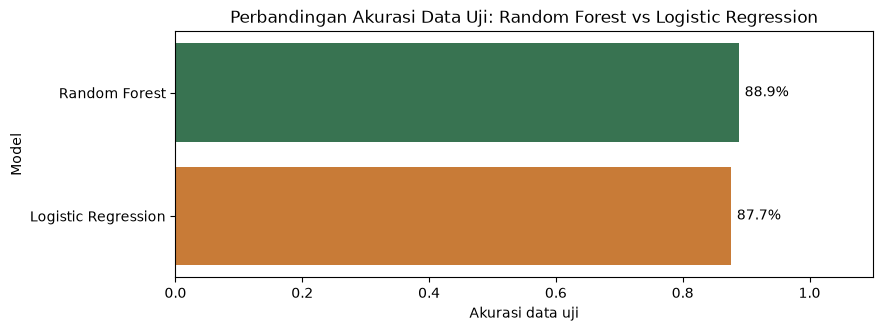

In [5]:
results_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Akurasi uji': list(results.values()),
}).sort_values(by='Akurasi uji', ascending=False).reset_index(drop=True)
print(results_df)
print(f"\nPembanding: menebak 'kebakaran' terus hanya benar {max(y.mean(), 1 - y.mean()):.4f}")

plt.figure(figsize=(9, 3.2))
ax = sns.barplot(data=results_df, x='Akurasi uji', y='Model', hue='Model', legend=False,
                 palette={'Random Forest': '#2E7D4F', 'Logistic Regression': '#E07A1F'})
for wadah in ax.containers:
    ax.bar_label(wadah, labels=[f'{v:.1%}' if v > 0 else '' for v in wadah.datavalues], padding=4)
plt.xlim(0, 1.1)
plt.xlabel("Akurasi data uji")
plt.title("Perbandingan Akurasi Data Uji: Random Forest vs Logistic Regression")
plt.show()

Model terbaik (berdasarkan akurasi uji): Random Forest


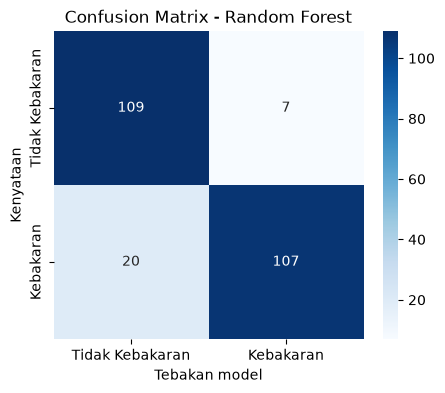

Baca: baris = kenyataan, kolom = tebakan model. Angka di kiri-bawah adalah hari kebakaran yang TERLEWAT.


In [6]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
best_pred = predictions[best_model_name]
print(f"Model terbaik (berdasarkan akurasi uji): {best_model_name}")

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Kebakaran', 'Kebakaran'], yticklabels=['Tidak Kebakaran', 'Kebakaran'])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Tebakan model"); plt.ylabel("Kenyataan")
plt.show()
print("Baca: baris = kenyataan, kolom = tebakan model. Angka di kiri-bawah adalah hari kebakaran yang TERLEWAT.")

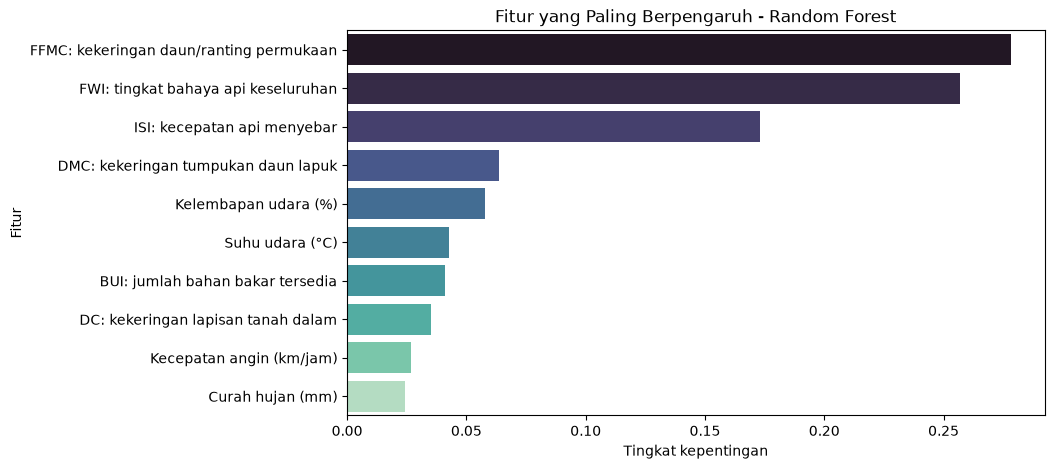

                                  Fitur  Tingkat kepentingan
FFMC: kekeringan daun/ranting permukaan             0.278426
    FWI: tingkat bahaya api keseluruhan             0.256906
            ISI: kecepatan api menyebar             0.173075
    DMC: kekeringan tumpukan daun lapuk             0.063486
                   Kelembapan udara (%)             0.057885
                        Suhu udara (°C)             0.042763
       BUI: jumlah bahan bakar tersedia             0.041122
     DC: kekeringan lapisan tanah dalam             0.035323
               Kecepatan angin (km/jam)             0.026600
                       Curah hujan (mm)             0.024413


<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

In [7]:
if best_model_name == "Random Forest":
    nilai = best_model.feature_importances_
    judul, kolom = "Fitur yang Paling Berpengaruh - Random Forest", 'Tingkat kepentingan'
else:
    nilai = np.abs(best_model.named_steps['logisticregression'].coef_[0])
    judul, kolom = "Fitur yang Paling Berpengaruh - Logistic Regression", 'Besar koefisien (abs)'

importance_df = pd.DataFrame({'Fitur': [nama_panjang[f] for f in X.columns], kolom: nilai}).sort_values(by=kolom, ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x=kolom, y='Fitur', hue='Fitur', palette='mako', legend=False)
plt.title(judul)
plt.show()
print(importance_df.to_string(index=False))
plt.figure(figsize=(9, 5))


### Catatan Penting

- Enam indeks kekeringan (FFMC sampai FWI) **dihitung dari data cuaca**, sehingga sebagian informasinya saling tumpang tindih. Itu sebabnya grafik di atas biasanya menunjukkan indeks lebih berpengaruh daripada cuaca mentah.
- Akurasi dihitung dari satu pembagian data uji (80:20), sehingga bisa sedikit berubah jika pembagiannya berbeda.
- File data tidak menjelaskan bagaimana label kebakaran ditentukan.
- Data berasal dari Aljazair, bukan Indonesia, sehingga model ini perlu dilatih ulang jika dipakai di tempat lain.

## 6. Penerapan (Dipakai untuk Hari Baru)

Model terbaik dipakai untuk menebak **satu hari baru**. Kamu akan mengisi **10 angka** satu per satu. Setiap isian
dilengkapi nama, penjelasan, dan **rentang angka di dataset**. Ketik angka dengan **titik** untuk desimal
(`0.5`, bukan `0,5`), tanpa satuan.

Sel pertama menampilkan **dua contoh hari asli** dari dataset (satu kebakaran, satu tidak) yang bisa diketik ulang.

In [8]:
contoh = pd.concat([df[df['Status'] == 'Kebakaran'].iloc[[20]], df[df['Status'] == 'Tidak Kebakaran'].iloc[[20]]])
tampil = contoh[fitur].rename(columns=nama_panjang).T
tampil.columns = ['Contoh: hari kebakaran', 'Contoh: hari tidak kebakaran']
tampil

,Contoh: hari kebakaran,Contoh: hari tidak kebakaran
Suhu udara (°C),32.0,25.0
Kelembapan udara (%),45.0,69.0
Kecepatan angin (km/jam),15.0,10.0
Curah hujan (mm),0.0,0.0
FFMC: kekeringan daun/ranting permukaan,90.2,86.7
DMC: kekeringan tumpukan daun lapuk,15.7,22.6
DC: kekeringan lapisan tanah dalam,67.8,84.2
ISI: kecepatan api menyebar,9.4,4.4
BUI: jumlah bahan bakar tersedia,19.9,27.1
FWI: tingkat bahaya api keseluruhan,13.3,8.5


In [ ]:
penjelasan = {
    'Suhu': 'Suhu udara siang hari.',
    'Kelembapan': 'Banyaknya uap air di udara. Makin kecil, makin kering.',
    'Angin': 'Kecepatan angin. Makin kencang, api makin cepat menyebar.',
    'Hujan': 'Curah hujan seharian. Isi 0 jika tidak hujan.',
    'FFMC': 'Kekeringan daun dan ranting kering di permukaan tanah. Makin besar, makin kering.',
    'DMC': 'Kekeringan tumpukan daun lapuk. Makin besar, makin kering.',
    'DC': 'Kekeringan lapisan tanah yang dalam (kemarau panjang). Makin besar, makin kering.',
    'ISI': 'Seberapa cepat api menyebar di awal. Makin besar, makin cepat.',
    'BUI': 'Jumlah bahan bakar (daun, ranting, serasah) yang bisa terbakar.',
    'FWI': 'Nilai bahaya api secara keseluruhan. Makin besar, makin berbahaya.',
}

print("=== Isi 10 Data untuk Prediksi ===\n")
input_values = {}
for i, f in enumerate(fitur, 1):
    while True:
        try:
            nilai = float(input(
                f"[{i}/10] {nama_panjang[f]}\n"
                f"       {penjelasan[f]}\n"
                f"       Rentang di dataset: {df[f].min():.1f} sampai {df[f].max():.1f}\n"
                f"       Isi angka: "))
            input_values[f] = nilai
            if not (df[f].min() <= nilai <= df[f].max()):
                print("       (peringatan: di luar rentang dataset, hasil kurang bisa diandalkan)")
            print()
            break
        except ValueError:
            print("       -> Harus berupa angka, coba lagi.\n")

data_user = pd.DataFrame([input_values])[fitur]
prediksi = best_model.predict(data_user)
peluang = best_model.predict_proba(data_user)

label_map = {0: "Tidak Kebakaran", 1: "Kebakaran"}
print("=== HASIL PREDIKSI ===")
print(f"Prediksi                 : {label_map[prediksi[0]]}")
print(f"Peluang Tidak Kebakaran  : {peluang[0][0]:.2%}")
print(f"Peluang Kebakaran        : {peluang[0][1]:.2%}")

=== Isi 10 Data untuk Prediksi ===



       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba lagi.

       -> Harus berupa angka, coba

## 7. Pemantauan

- **Pantau hasil:** bandingkan tebakan model dengan kejadian kebakaran sebenarnya, lalu hitung ulang akurasinya secara berkala.
- **Data tempat lain:** model dilatih dengan data Aljazair. Untuk daerah lain, latih ulang dengan data lokal.
- **Sumber isian:** enam indeks (FFMC, DMC, DC, ISI, BUI, FWI) perlu dihitung dari sistem peringatan kebakaran atau
  dari stasiun cuaca. Tanpa itu, isian untuk model ini tidak lengkap.
- **Cuaca berubah:** pola cuaca bergeser dari tahun ke tahun, jadi model perlu diperbarui.

## Kesimpulan

In [ ]:
r = results_df.set_index('Model')
rf, lr = r.loc['Random Forest'], r.loc['Logistic Regression']
print(f"1. Model terbaik: {best_model_name} (dipilih dari akurasi data uji).")
print(f"2. Akurasi uji: Random Forest {rf['Akurasi uji']:.1%} | Logistic Regression {lr['Akurasi uji']:.1%}")
print("3. Selisih kedua model kecil, jadi keduanya cukup mirip.")
print(f"4. Fitur paling berpengaruh: {importance_df.iloc[0]['Fitur']}.")
print("5. Keterbatasan: data dari Aljazair, bukan Indonesia, dan enam indeks perlu dihitung tersendiri.")

1. Model terbaik: Random Forest (dipilih dari akurasi data uji).
2. Akurasi uji: Random Forest 88.9% | Logistic Regression 87.7%
3. Selisih kedua model kecil, jadi keduanya cukup mirip.
4. Fitur paling berpengaruh: FFMC: kekeringan daun/ranting permukaan.
5. Keterbatasan: data dari Aljazair, bukan Indonesia, dan enam indeks perlu dihitung tersendiri.
